데이터셋 준비

In [ ]:
# 1. 구글 드라이브와 코랩 연동하기 (마운트)
# 실행하면 팝업창이 뜰 텐데, '구글 드라이브에 연결' 누르고 권한 허용해 주면 돼!
from google.colab import drive
drive.mount('/content/drive')

# 2. 압축을 해제해서 저장할 코랩 내부 workspace 폴더 만들기
!mkdir -p /content/workspace

# 3. 구글 드라이브에 있는 dataset.zip을 코랩 workspace 폴더에 풀기
# (-q 옵션을 주면 수천 장의 파일 이름이 화면에 도배되는 걸 막아줘서 웹 브라우저 렉이 안 걸려!)
!unzip -q "/content/drive/MyDrive/dataset.zip" -d /content/workspace/

# 4. 압축이 진짜 잘 풀렸는지 최종 파일 개수 확인하기
import os
result_files = os.listdir('/content/workspace')
print("\n" + "="*40)
print(f"🎉 압축 해제 완료! 현재 workspace 폴더 안의 파일 개수: {len(result_files)}개")
print("="*40)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🎉 압축 해제 완료! 현재 workspace 폴더 안의 파일 개수: 1개


전처리 과정

1. 이미지 로드 및 그레이스케일 변환

총 3482개의 이미지 파일을 찾음
📦 현재 로드한 이미지 위치: dataset/ADVE/0000136188.jpg


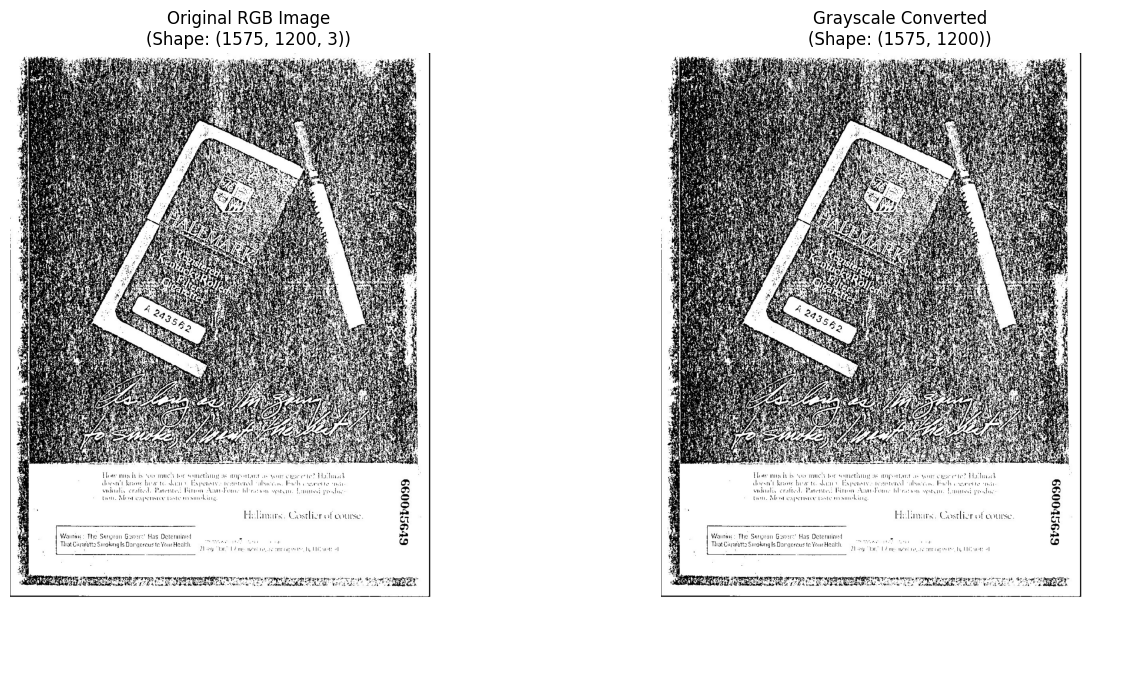


원본 이미지 행렬 형태 (가로, 세로, 채널): (1575, 1200, 3)
변환 후 이미지 행렬 형태 (가로, 세로): (1575, 1200)
이미지를 정상적으로 가져와 1채널로 변환 완료


In [ ]:
import cv2
import os
import glob
import matplotlib.pyplot as plt

# 1. 데이터셋 최상위 폴더 경로 설정
DATASET_PATH = '/content/workspace/dataset'

# 2. 이미지 파일 경로 싹 긁어오기
img_extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff']
img_paths = []

for ext in img_extensions:
    # 대소문자 구분 없이 찾기 위해 lower, upper 둘 다 대응하도록 glob 패턴 확장
    img_paths.extend(glob.glob(os.path.join(DATASET_PATH, '**', ext), recursive=True))
    img_paths.extend(glob.glob(os.path.join(DATASET_PATH, '**', ext.upper()), recursive=True))

# 파일 경로 정렬
img_paths = sorted(list(set(img_paths)))

if not img_paths:
    print("이미지 파일 X")
    print(f"현재 탐색한 최상위 경로: {DATASET_PATH}")
    print("정확한 경로를 다시 확인")
else:
    print(f"총 {len(img_paths)}개의 이미지 파일을 찾음")

    # 테스트할 첫 번째 이미지의 전체 경로 가져오기
    test_img_path = img_paths[0]

    # 어떤 하위 폴더에서 가져왔는지 눈으로 확인하기 위해 상대 경로 추출
    relative_path = os.path.relpath(test_img_path, DATASET_PATH)
    print(f"📦 현재 로드한 이미지 위치: dataset/{relative_path}")

    # 3. OpenCV를 이용해 이미지 로드 (BGR)
    src_bgr = cv2.imread(test_img_path)

    # 4. 명시적 그레이스케일 변환 (3채널 BGR -> 1채널 Gray)
    gray_img = cv2.cvtColor(src_bgr, cv2.COLOR_BGR2GRAY)

    # 5. Matplotlib 시각화 비교 출력
    src_rgb = cv2.cvtColor(src_bgr, cv2.COLOR_BGR2RGB)
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    # [왼쪽] 원본 이미지 출력
    axes[0].imshow(src_rgb)
    axes[0].set_title(f"Original RGB Image\n(Shape: {src_bgr.shape})", fontsize=12)
    axes[0].axis('off')

    # [오른쪽] 그레이스케일 변환 이미지 출력
    axes[1].imshow(gray_img, cmap='gray')
    axes[1].set_title(f"Grayscale Converted\n(Shape: {gray_img.shape})", fontsize=12)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

    # 6. 차원(Channel) 검증 프린트
    print("\n" + "="*55)
    print(f"원본 이미지 행렬 형태 (가로, 세로, 채널): {src_bgr.shape}")
    print(f"변환 후 이미지 행렬 형태 (가로, 세로): {gray_img.shape}")
    print("이미지를 정상적으로 가져와 1채널로 변환 완료")
    print("="*55)

2. 미세 기울기 보정

탐지한 미세 기울기 각도: 1.81도


/tmp/ipykernel_1444/307397409.py:55: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1444/307397409.py:55: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


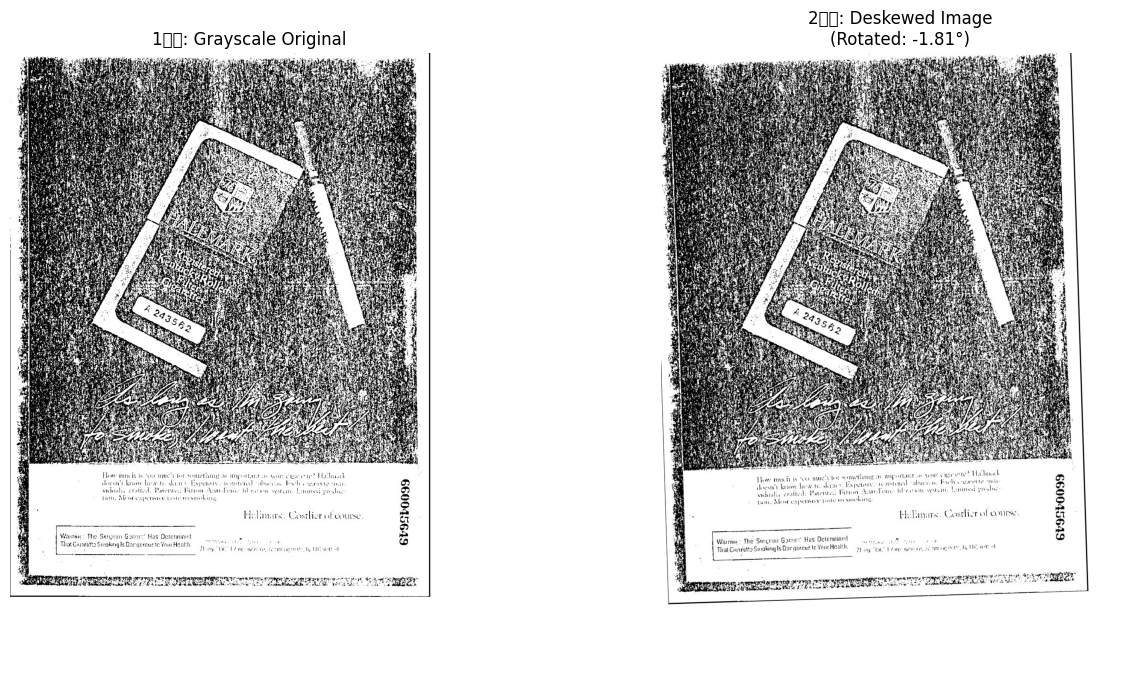

미세 기울기 보정 프로세스 정상적으로 완료


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

if 'gray_img' not in locals():
    print("[에러]")
else:
    # 1. 캐니 에지 검출 (Canny Edge Detection)
    # 이미지에서 글자들의 외곽선(선 성분)만 뼈대처럼 추출합니다.
    edges = cv2.Canny(gray_img, 50, 150, apertureSize=3)

    # 2. 확률적 허프 선 변환 (Probabilistic Hough Line Transform)
    # 에지 성분 중에서 진짜 '직선'인 녀석들을 찾아내 각도를 계산합니다.
    lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=100, minLineLength=100, maxLineGap=10)

    angles = []
    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line[0]
            # 각 직선의 기울기 각도(라디안 -> 도) 계산
            angle = np.arctan2(y2 - y1, x2 - x1) * 180.0 / np.pi

            # 수평선에 가까운 미세한 기울기(-45도 ~ 45도 사이)만 필터링해서 수집
            if -45 < angle < 45:
                angles.append(angle)

    # 3. 대표 기울기 산출 및 회전 행렬 계산
    median_angle = np.median(angles) if angles else 0.0
    print(f"탐지한 미세 기울기 각도: {median_angle:.2f}도")

    # 4. 이미지 아핀 변환 (Affined Rotation)
    (h, w) = gray_img.shape[:2]
    center = (w // 2, h // 2)

    # 회전 매트릭스 생성 (마지막 인자는 스케일 비율, 1.0은 원본 크기 유지)
    rotation_matrix = cv2.getRotationMatrix2D(center, median_angle, 1.0)

    # 실제 회전 적용 (배경은 깔끔하게 하얀색(255)으로 채웁니다)
    deskewed_img = cv2.warpAffine(gray_img, rotation_matrix, (w, h),
                                  flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_CONSTANT, borderValue=255)

    # 5. 시각화 비교 출력
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    # [왼쪽] 1단계 그레이스케일 원본
    axes[0].imshow(gray_img, cmap='gray')
    axes[0].set_title("1단계: Grayscale Original", fontsize=12)
    axes[0].axis('off')

    # [오른쪽] 2단계 기울기 보정 완료본
    axes[1].imshow(deskewed_img, cmap='gray')
    axes[1].set_title(f"2단계: Deskewed Image\n(Rotated: {-median_angle:.2f}°)", fontsize=12)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
    print("미세 기울기 보정 프로세스 정상적으로 완료")

3. 가우시안 블러

/tmp/ipykernel_1444/1337368531.py:33: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1444/1337368531.py:33: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


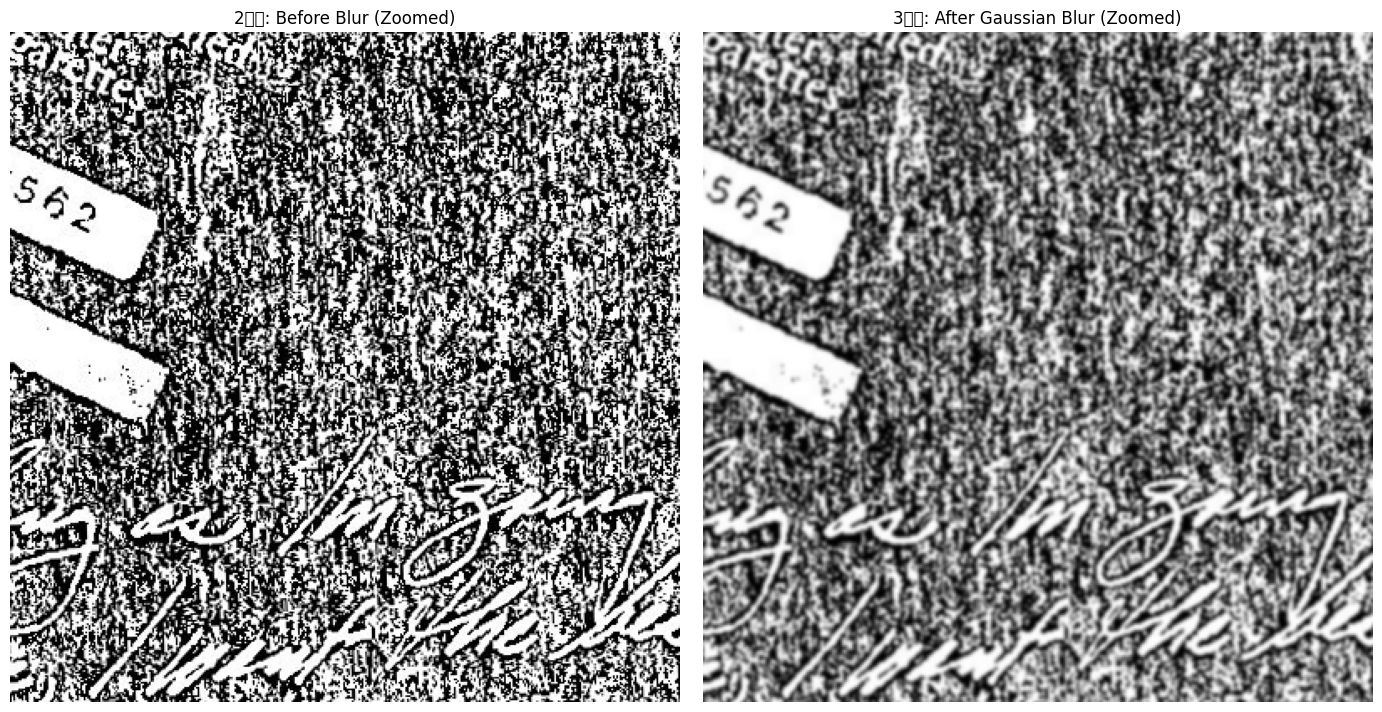

가우시안 블러 노이즈 필터링이 완료


In [ ]:
import cv2
import matplotlib.pyplot as plt

if 'deskewed_img' not in locals():
    print("[에러]")
else:
    # 1. 가우시안 블러 적용
    # ksize=(5, 5)는 가우시안 커널의 가로세로 크기입니다
    # 0은 가우시안 분포의 표준편차(sigmaX)를 커널 크기에 맞춰 자동으로 계산하라는 의미입니다
    blurred_img = cv2.GaussianBlur(deskewed_img, ksize=(5, 5), sigmaX=0)

    # 2. 시각화 비교 출력
    # 이미지 정중앙 부분을 조금 확대해서 블러 효과 확연하게 확인
    h, w = blurred_img.shape
    cy, cx = h // 2, w // 2
    crop_size = 200

    gray_crop = deskewed_img[cy-crop_size:cy+crop_size, cx-crop_size:cx+crop_size]
    blur_crop = blurred_img[cy-crop_size:cy+crop_size, cx-crop_size:cx+crop_size]

    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    # [왼쪽] 블러 전 (2단계 보정본 확대)
    axes[0].imshow(gray_crop, cmap='gray')
    axes[0].set_title("2단계: Before Blur (Zoomed)", fontsize=12)
    axes[0].axis('off')

    # [오른쪽] 블러 후 (3단계 완료본 확대)
    axes[1].imshow(blur_crop, cmap='gray')
    axes[1].set_title("3단계: After Gaussian Blur (Zoomed)", fontsize=12)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
    print("가우시안 블러 노이즈 필터링이 완료")

4. 적응형 이진화

/tmp/ipykernel_1444/1122681142.py:37: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1444/1122681142.py:37: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


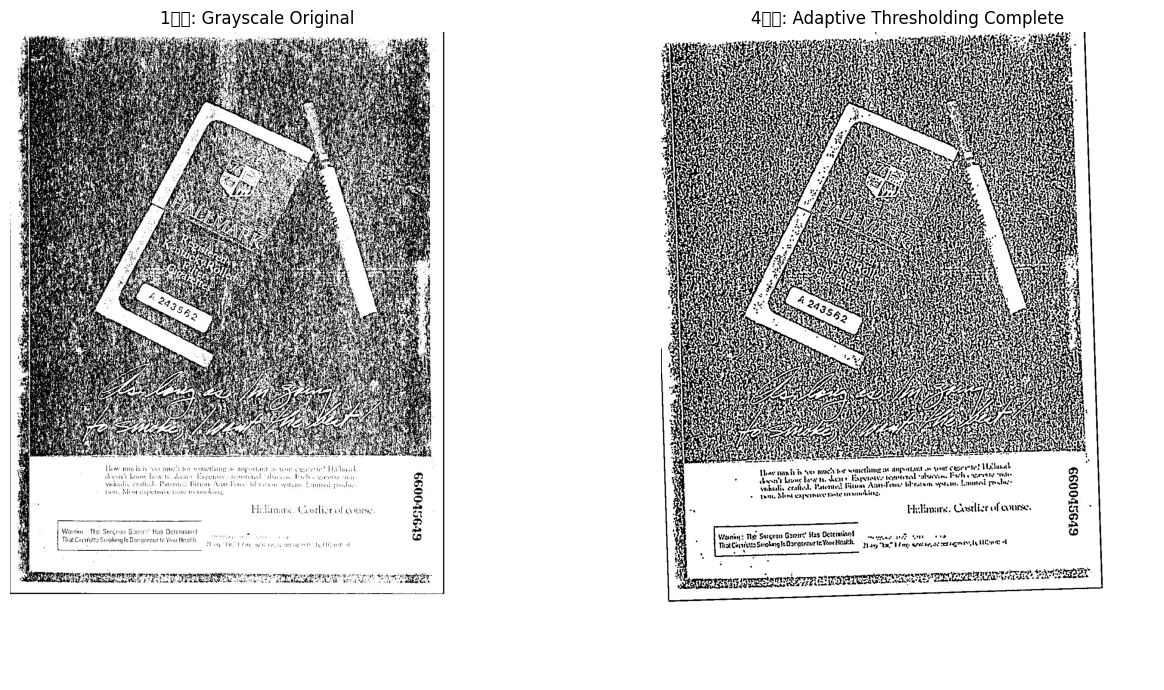

전처리의 마지막 적응형 이진화 완료


In [ ]:
import cv2
import matplotlib.pyplot as plt

if 'blurred_img' not in locals():
    print("[에러]")
else:
    # 1. 적응형 이진화 (Adaptive Thresholding) 적용
    # - maxValue=255: 조건에 만족하는(배경) 픽셀을 순백색으로 채움
    # - adaptiveMethod: 주변 영역의 가우시안 가중치 평균을 사용해 임계값 결정
    # - thresholdType=THRESH_BINARY: 기준보다 밝으면 흰색, 어두우면 검은색(글자)
    # - blockSize=11: 주변 환경을 살필 11x11 픽셀 크기의 국소 영역 설정 (홀수만 가능)
    # - C=2: 계산된 평균값에서 2를 빼서 경계선을 더 선명하고 깔끔하게 보정
    adaptive_thresh = cv2.adaptiveThreshold(
        blurred_img,
        maxValue=255,
        adaptiveMethod=cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        thresholdType=cv2.THRESH_BINARY,
        blockSize=11,
        C=2
    )

    # 2. 시각화 비교 출력
    # 전체적인 이진화 퀄리티를 확인하기 위해 원본 스케일과 나란히 비교합니다.
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))

    # [왼쪽] 전처리 전 (1단계 그레이스케일 원본)
    axes[0].imshow(gray_img, cmap='gray')
    axes[0].set_title("1단계: Grayscale Original", fontsize=12)
    axes[0].axis('off')

    # [오른쪽] 4단계 적응형 이진화 완료본
    # 이제 회색조나 얼룩은 사라지고 완벽한 흑/백(0과 255)만 남았습니다.
    axes[1].imshow(adaptive_thresh, cmap='gray')
    axes[1].set_title("4단계: Adaptive Thresholding Complete", fontsize=12)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()
    print("전처리의 마지막 적응형 이진화 완료")

전처리 완료

데이터셋 이미지 전체 전처리

In [ ]:
import cv2
import os
import glob
from tqdm.notebook import tqdm

# 1. 경로 설정
SRC_DIR = '/content/workspace/dataset'
TAR_DIR = '/content/workspace/preprocessed_dataset'

# 2. 원본 이미지 경로 싹 긁어오기
img_extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff']
img_paths = []
for ext in img_extensions:
    img_paths.extend(glob.glob(os.path.join(SRC_DIR, '**', ext), recursive=True))
    img_paths.extend(glob.glob(os.path.join(SRC_DIR, '**', ext.upper()), recursive=True))
img_paths = sorted(list(set(img_paths)))

print(f"총 {len(img_paths)}장의 이미지 전처리중...")

# 3. 반복문으로 3천 장 논스톱 전처리 시작 (tqdm으로 진행률 바 표시)
for path in tqdm(img_paths, desc="전처리 진행률"):
    try:
        # (1) 이미지 로드 및 그레이스케일 변환
        src = cv2.imread(path)
        gray = cv2.cvtColor(src, cv2.COLOR_BGR2GRAY)

        # (2) 미세 기울기 보정 (허프 변환)
        edges = cv2.Canny(gray, 50, 150, apertureSize=3)
        lines = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=100, minLineLength=100, maxLineGap=10)

        angles = []
        if lines is not None:
            for line in lines:
                x1, y1, x2, y2 = line[0]
                angle = np.arctan2(y2 - y1, x2 - x1) * 180.0 / np.pi
                if -45 < angle < 45:
                    angles.append(angle)

        median_angle = np.median(angles) if angles else 0.0
        (h, w) = gray.shape[:2]
        center = (w // 2, h // 2)
        rotation_matrix = cv2.getRotationMatrix2D(center, median_angle, 1.0)
        deskewed = cv2.warpAffine(gray, rotation_matrix, (w, h),
                                  flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_CONSTANT, borderValue=255)

        # (3) 가우시안 블러 노이즈 제거
        blurred = cv2.GaussianBlur(deskewed, ksize=(5, 5), sigmaX=0)

        # (4) 적응형 이진화 (최종 결과물)
        final_preprocessed = cv2.adaptiveThreshold(
            blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2
        )

        # (5) 하위 폴더 구조를 그대로 유지하며 저장 경로 생성
        rel_path = os.path.relpath(path, SRC_DIR)  # 예: 'News/0001.jpg'
        save_path = os.path.join(TAR_DIR, rel_path)

        # 저장할 폴더가 없으면 자동 생성 (예: preprocessed_dataset/News/ 폴더 생성)
        os.makedirs(os.path.dirname(save_path), exist_ok=True)

        # 전처리 완료된 흑백 이미지 저장
        cv2.imwrite(save_path, final_preprocessed)

    except Exception as e:
        print(f"🚨 파일 처리 중 에러 발생 ({os.path.basename(path)}): {e}")

print("\n" + "="*50)
print(f"모든 파일이 '{TAR_DIR}' 폴더에 저장")
print("="*50)

총 3482장의 이미지 전처리중...


전처리 진행률:   0%|          | 0/3482 [00:00<?, ?it/s]


모든 파일이 '/content/workspace/preprocessed_dataset' 폴더에 저장


1. CRAFT 텍스트 영역 탐지

In [ ]:
!pip install easyocr -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 49.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 978.2/978.2 kB 52.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.6/299.6 kB 28.2 MB/s eta 0:00:00


탐지 가동할 전처리 이미지: ADVE/0000136188.jpg
Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete내장된 CRAFT 엔진으로 글자 울타리(Bounding Box)를 따내는 중...


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


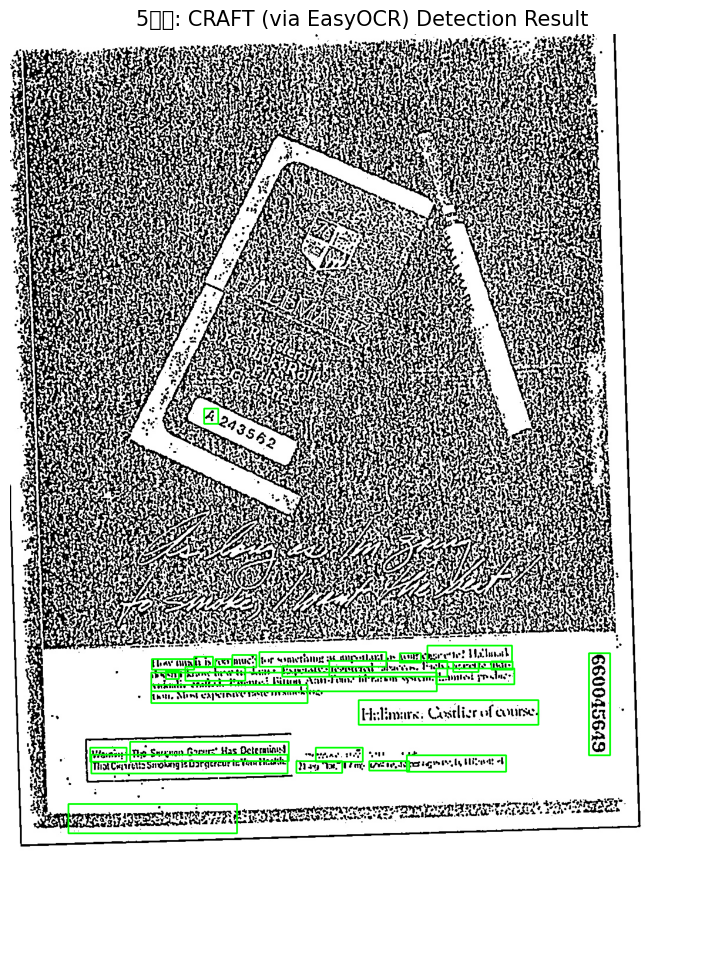


CRAFT 탐지 완료
이미지 안에서 총 27개의 단어 구역을 분리했습니다.
분리된 단어 조각 저장 위치: /content/workspace/craft_result/0000136188_crops


In [ ]:
import os
import glob
import cv2
import easyocr
import matplotlib.pyplot as plt

# 1. [입력] 전처리 완료 폴더 및 [출력] 결과 폴더 경로 설정
PREPROCESSED_DIR = '/content/workspace/preprocessed_dataset'
OUTPUT_DIR = '/content/workspace/craft_result'
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 2. 이미지 파일 경로 싹 긁어오기
img_extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff']
processed_paths = []
for ext in img_extensions:
    processed_paths.extend(glob.glob(os.path.join(PREPROCESSED_DIR, '**', ext), recursive=True))
    processed_paths.extend(glob.glob(os.path.join(PREPROCESSED_DIR, '**', ext.upper()), recursive=True))
processed_paths = sorted(list(set(processed_paths)))

if not processed_paths:
    print("전처리된 폴더에서 이미지를 찾을 수 없습니다")
else:
    # 테스트로 첫 번째 이미지 선택
    test_img_path = processed_paths[0]
    filename = os.path.basename(test_img_path)
    name, ext = os.path.splitext(filename)

    print(f"탐지 가동할 전처리 이미지: {os.path.relpath(test_img_path, PREPROCESSED_DIR)}")

    # 3. EasyOCR 리더 초기화 (영어 문서 기조, GPU 가속 활성화)
    # 내부적으로 완벽하게 검증된 CRAFT 모델 가중치를 안전하게 로드합니다.
    reader = easyocr.Reader(['en'], gpu=True)

    # 4. 내장된 CRAFT 엔진으로 텍스트 영역 탐지 (detect 옵션)
    print("내장된 CRAFT 엔진으로 글자 울타리(Bounding Box)를 따내는 중...")
    horizontal_boxes, free_boxes = reader.detect(test_img_path)
    boxes = horizontal_boxes[0]  # 가로 텍스트 박스 좌표 추출

    # 5. 결과 시각화 및 단어 조각 자르기 (Crop)
    img = cv2.imread(test_img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 단어 조각들을 저장할 crops 폴더 생성
    crop_dir = os.path.join(OUTPUT_DIR, f"{name}_crops")
    os.makedirs(crop_dir, exist_ok=True)

    # 찾아낸 박스 좌표를 돌면서 사각형을 그리고 크롭 저장
    for i, box in enumerate(boxes):
        # box: [x_min, x_max, y_min, y_max] 구조
        x_min, x_max, y_min, y_max = int(box[0]), int(box[1]), int(box[2]), int(box[3])

        # 원본 이미지에 초록색 사각형 그리기
        cv2.rectangle(img_rgb, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)

        # 6단계를 위해 단어별로 조각 이미지 자르기 (Crop)
        crop_img = img[y_min:y_max, x_min:x_max]
        if crop_img.size > 0:
            cv2.imwrite(os.path.join(crop_dir, f"crop_{i:04d}.jpg"), crop_img)

    # 결과 화면 출력
    plt.figure(figsize=(12, 12))
    plt.imshow(img_rgb)
    plt.title("5단계: CRAFT (via EasyOCR) Detection Result", fontsize=15)
    plt.axis('off')
    plt.show()

    print("\n" + "="*50)
    print(f"CRAFT 탐지 완료")
    print(f"이미지 안에서 총 {len(boxes)}개의 단어 구역을 분리했습니다.")
    print(f"분리된 단어 조각 저장 위치: {crop_dir}")
    print("="*50)

CRNN
easyocr 프레임워크를 영리하게 세팅해 뒀기 때문에 현재 단계 역시 복잡한 레이어 구현 없이 리더 객체의 readtext 엔진을 가동하면 한 방에 텍스트 추출까지 다이렉트로 연결

CRNN 인공지능 문자 인식 엔진 시작...

📝 [0000136188.jpg] 최종 텍스트 추출 결과
번호    | 인식된 텍스트                        | 신뢰도            
------------------------------------------------------------
1     | 4                              | 99.63%
2     | it 6>                          | 11.55%
3     | 45'                            | 10.19%
4     | mua                            | 9.14%
5     | br ~nitiinng : nuri,           | 0.72%
6     | 14+u;                          | 1.10%
7     | sr*1c' Ilual                   | 3.23%
8     | Huav' 4bhbn                    | 0.80%
9     | Wttazet/ #ua"tsc: Fih          | 1.03%
10    | 504                            | 8.14%
11    | Ikfue                          | 6.35%
12    | A1                             | 8.02%
13    | Lrbts"=                        | 5.54%
14    | Ptiett"                        | 0.65%
15    | Lanisi jrsl ;                  | 2.93%
16    | SuRii ~oIS  %cnta? Hilu H  %u1-Fin' hrtvh syloms | 0.01%
17    | Iaanerinut" Iaste /sund =      | 1.43%
18  

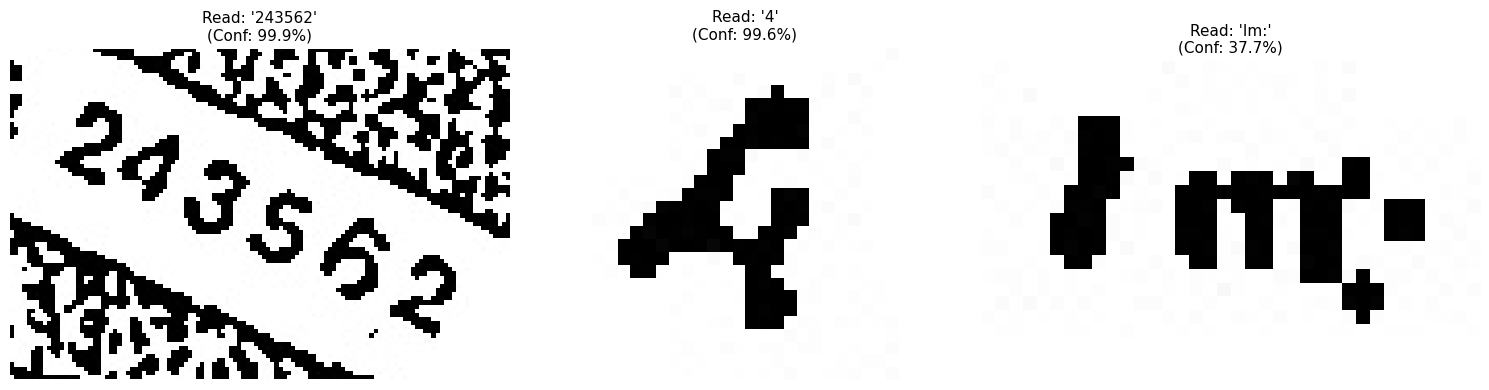

In [ ]:
import cv2
import easyocr
import matplotlib.pyplot as plt

# 5단계에서 사용했던 테스트 이미지 경로와 리더 객체를 그대로 이어받습니다
# (만약 세션이 끊겼다면 reader = easyocr.Reader(['en'], gpu=True)를 다시 실행해 주면 돼)
if 'test_img_path' not in locals() or 'reader' not in locals():
    print("[에러]")
else:
    print("CRNN 인공지능 문자 인식 엔진 시작...")

    # easyocr.Reader의 readtext는 탐지(CRAFT)와 인식(CRNN)을 동시에 수행하여
    # 최종 텍스트 결과와 신뢰도(Confidence)를 한 번에 반환해 줍니다.
    results = reader.readtext(test_img_path)

    print("\n" + "="*60)
    print(f"📝 [{os.path.basename(test_img_path)}] 최종 텍스트 추출 결과")
    print("="*60)
    print(f"{'번호':<5} | {'인식된 텍스트':<30} | {'신뢰도':<15}")
    print("-"*60)

    # 추출된 결과를 상위 20개만 정갈하게 출력해보기
    for i, res in enumerate(results[:20]):
        bbox, text, prob = res
        # 신뢰도(prob)는 0~1 사이 값이므로 보기 편하게 퍼센트(%)로 변환
        print(f"{i+1:<5} | {text:<30} | {prob*100:.2f}%")

    print("-"*60)
    if len(results) > 20:
        print(f"... {len(results) - 20}개의 단어가 더 성공적으로 추출")
    print("="*60)

    # 맛보기 시각화: 제일 잘 읽은 단어 3개만 이미지 조각과 함께 화면에 띄워보기
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    img = cv2.imread(test_img_path)

    # 신뢰도가 높은 순으로 정렬해서 상위 3개 크롭 이미지 보여주기
    sorted_results = sorted(results, key=lambda x: x[2], reverse=True)

    for idx, res in enumerate(sorted_results[:3]):
        bbox, text, prob = res
        # bbox 좌표: [[top_left], [top_right], [bottom_right], [bottom_left]]
        x_min = int(min([p[0] for p in bbox]))
        x_max = int(max([p[0] for p in bbox]))
        y_min = int(min([p[1] for p in bbox]))
        y_max = int(max([p[1] for p in bbox]))

        crop = img[y_min:y_max, x_min:x_max]
        if crop.size > 0:
            crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)
            axes[idx].imshow(crop_rgb)
            axes[idx].set_title(f"Read: '{text}'\n(Conf: {prob*100:.1f}%)", fontsize=11)
        axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

최종 텍스트 추출

In [ ]:
import os
import glob
import easyocr
from tqdm.notebook import tqdm

# 1. 경로 세팅
PREPROCESSED_DIR = '/content/workspace/preprocessed_dataset'
FINAL_TXT_PATH = '/content/workspace/ocr_final_results.txt'

# 2. EasyOCR 인공지능 리더 스탠바이
reader = easyocr.Reader(['en'], gpu=True)

# 3. 전처리 폴더 안의 3천여 장 이미지 싹 다 긁어오기
img_extensions = ['*.jpg', '*.jpeg', '*.png', '*.bmp', '*.tif', '*.tiff']
processed_paths = []
for ext in img_extensions:
    processed_paths.extend(glob.glob(os.path.join(PREPROCESSED_DIR, '**', ext), recursive=True))
    processed_paths.extend(glob.glob(os.path.join(PREPROCESSED_DIR, '**', ext.upper()), recursive=True))
processed_paths = sorted(list(set(processed_paths)))

print(f"{len(processed_paths)}장의 이미지에서 문자를 추출하여 저장중...")

# 4. 파일 쓰기 모드로 열어서 대량 추출 시작 (게이지 바 가동)
with open(FINAL_TXT_PATH, 'w', encoding='utf-8') as f:
    for path in tqdm(processed_paths, desc="최종 텍스트 추출률"):
        try:
            # 상대 경로 추출 (예: News/0001.jpg)
            rel_path = os.path.relpath(path, PREPROCESSED_DIR)

            # 5&6단계 동시 가동 (CRAFT + CRNN)
            outputs = reader.readtext(path)

            # 추출된 단어들을 한 줄의 문장으로 합성
            extracted_words = [res[1] for res in outputs]
            combined_text = " ".join(extracted_words)

            # 텍스트 파일에 [파일경로] 정제된 텍스트 형태로 누적 저장
            f.write(f"[{rel_path}] {combined_text}\n")

        except Exception as e:
            print(f"{os.path.basename(path)} 처리 중 에러 발생: {e}")

print("\n" + "="*60)
print(f"모든 텍스트가 '{FINAL_TXT_PATH}'에 최종 저장되었습니다!!")
print("="*60)

3482장의 이미지에서 문자를 추출하여 저장중...


최종 텍스트 추출률:   0%|          | 0/3482 [00:00<?, ?it/s]


모든 텍스트가 '/content/workspace/ocr_final_results.txt'에 최종 저장되었습니다!!


📊 [OCR 최종 추출 결과 통계]
✔ 총 처리된 이미지 수: 3482장
✔ 총 추출된 글자 수: 4,661,817자
✔ 이미지당 평균 글자 수: 1338.8자
✔ 최대 글자 추출 이미지: 8803자


/tmp/ipykernel_3102/369425046.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top10, x='text_length', y='short_name', palette='Blues_r', edgecolor='grey')


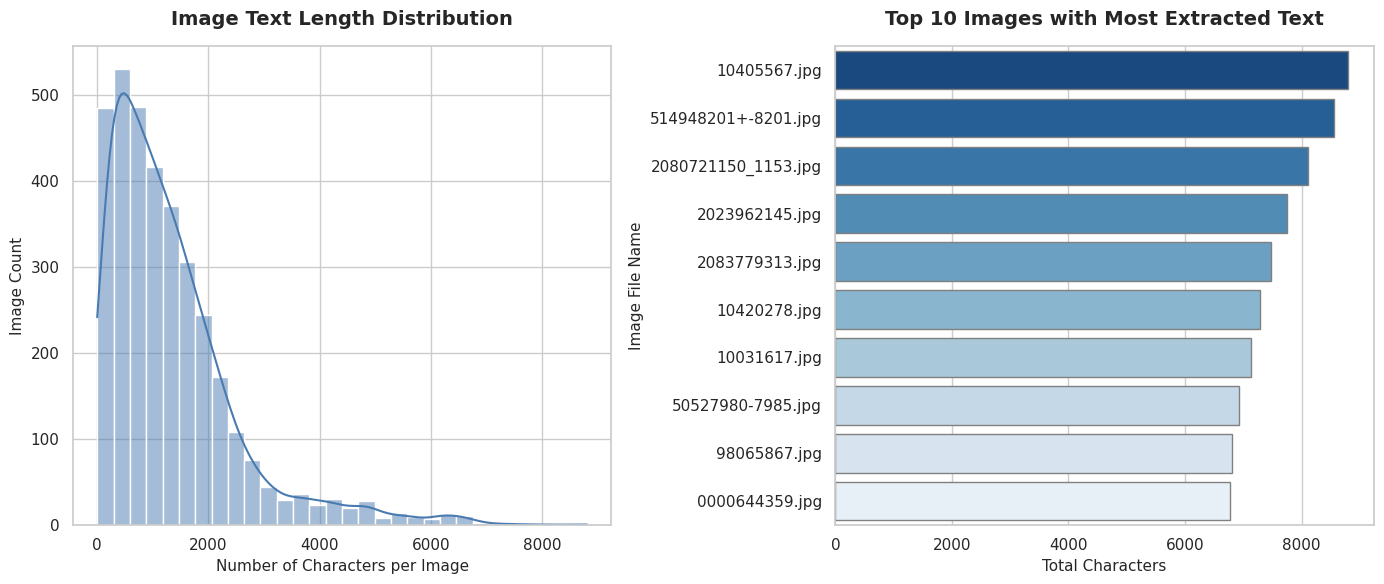


✨ 시각화 그래프가 '/content/ocr_analysis_chart.png' 경로로 성공적으로 저장되었습니다!


In [ ]:
import re
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# 1. 데이터 불러오기 및 파싱
file_path = '/content/ocr_final_results.txt'  # 코랩 내 실제 경로로 확인해줘!
# 만약 현재 폴더에 있다면 'ocr_final_results.txt' 로 변경

data = []
with open(file_path, 'r', encoding='utf-8') as f:
    content = f.read()

# [파일명.jpg] 텍스트 형식 파싱 정규식
matches = re.findall(r'\[(.*?)\] (.*?)(?=\n\[|$)', content, re.DOTALL)

for match in matches:
    file_name = match[0]
    ocr_text = match[1].strip()
    char_count = len(ocr_text)
    # 특수문자 비율 계산 (인식 품질 노이즈 확인용)
    special_chars = len(re.findall(r'[^a-zA-Z0-9\sㄱ-ㅣ가-힣]', ocr_text))
    special_ratio = (special_chars / char_count * 100) if char_count > 0 else 0

    data.append({
        'file_name': file_name,
        'text_length': char_count,
        'special_char_ratio': special_ratio
    })

df = pd.DataFrame(data)

# 2. 통계치 계산 (PPT 장식용 데이터)
print("="*50)
print(f"📊 [OCR 최종 추출 결과 통계]")
print(f"✔ 총 처리된 이미지 수: {len(df)}장")
print(f"✔ 총 추출된 글자 수: {df['text_length'].sum():,}자")
print(f"✔ 이미지당 평균 글자 수: {df['text_length'].mean():.1f}자")
print(f"✔ 최대 글자 추출 이미지: {df['text_length'].max()}자")
print("="*50)

# 3. PPT 전용 세련된 시각화 그래프 그리기
plt.figure(figsize=(14, 6))
sns.set_theme(style="whitegrid")

# 그래프 1: 이미지별 글자 수 분포 (히스토그램)
plt.subplot(1, 2, 1)
sns.histplot(data=df, x='text_length', bins=30, color='#4A7BB0', kde=True, edgecolor='white')
plt.title('Image Text Length Distribution', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Number of Characters per Image', fontsize=11)
plt.ylabel('Image Count', fontsize=11)

# 그래프 2: OCR 인식 텍스트 길이 상위 Top 10 이미지 (바 차트)
plt.subplot(1, 2, 2)
top10 = df.nlargest(10, 'text_length')
# 파일명이 길면 깨지므로 뒷부분만 추출
top10['short_name'] = top10['file_name'].apply(lambda x: x.split('/')[-1])

sns.barplot(data=top10, x='text_length', y='short_name', palette='Blues_r', edgecolor='grey')
plt.title('Top 10 Images with Most Extracted Text', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Total Characters', fontsize=11)
plt.ylabel('Image File Name', fontsize=11)

# 레이아웃 조정 및 저장
plt.tight_layout()
plt.savefig('/content/ocr_analysis_chart.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✨ 시각화 그래프가 '/content/ocr_analysis_chart.png' 경로로 성공적으로 저장되었습니다!")